# 03.4 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/03-classification/04-logistic-regression/solutions.ipynb)

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

cust20 = pd.read_csv(data_path("shopwave_customers_small.csv"))
X20 = cust20[["visits_last_month", "days_since_last"]]
y20 = cust20["churned"]
cust20

,customer_id,visits_last_month,items_last_month,days_since_last,country,spend_next_month,churned
0,C001,2,2,55,UK,27.61,1
1,C002,11,8,44,FR,220.42,0
2,C003,10,6,22,DE,176.21,0
3,C004,7,6,58,UK,127.58,1
4,C005,7,5,25,FR,150.95,1
5,C006,13,7,20,FR,250.03,0
6,C007,2,2,54,UK,47.33,1
7,C008,10,5,22,UK,196.92,0
8,C009,3,3,5,DE,94.82,1
9,C010,2,1,28,UK,45.05,1


## Exercise 1

$\sigma(1) = 1/(1 + e^{-1}) = 1/1.368 = 0.731$; $\sigma(-1) = 0.269$; $\sigma(5) = 1/(1 + 0.0067) = 0.993$.

Churner at 0.7: $-\ln 0.7 = 0.357$. Stayer at 0.7: $-\ln(1 - 0.7) = -\ln 0.3 = 1.204$.

In [2]:
def sigmoid(z): return 1 / (1 + np.exp(-z))
print([round(sigmoid(z), 3) for z in [1, -1, 5]])
print(round(-np.log(0.7), 3), round(-np.log(0.3), 3))

[np.float64(0.731), np.float64(0.269), np.float64(0.993)]
0.357 1.204


## Exercise 2

$0 = 3.13 - 0.60 \times 8 + 0.052 \times \text{days} = -1.67 + 0.052\,\text{days}$, so $\text{days} = 1.67 / 0.052 \approx 32$. A customer with 8 visits tips into "churn" after about a month of silence.

In [3]:
from sklearn.linear_model import LogisticRegression
logit = LogisticRegression().fit(X20, y20)
c = logit.intercept_[0]; mv, md_ = logit.coef_[0]
days_at_half = -(c + mv * 8) / md_
print(f"crossing at {days_at_half:.1f} days")
for d in [days_at_half - 5, days_at_half + 5]:
    print(f"  days={d:.0f}: p̂ = {sigmoid(c + mv * 8 + md_ * d):.2f}")

crossing at 32.3 days
  days=27: p̂ = 0.44
  days=37: p̂ = 0.56


## Exercise 3

In [4]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail
from sklearn.model_selection import train_test_split

raw = pd.read_excel(ensure_online_retail(), sheet_name="Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830


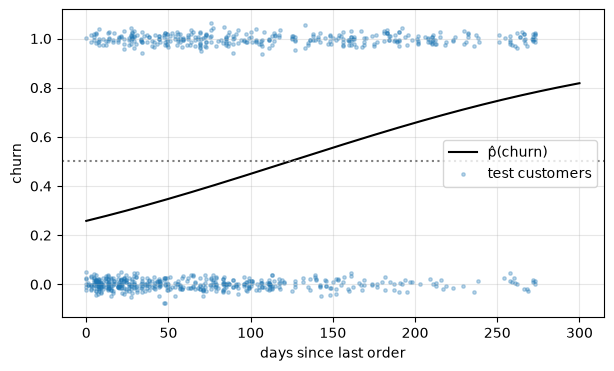

p̂ = 0.5 at 124 days; test accuracy 64.9%


In [5]:
one = LogisticRegression(max_iter=1000).fit(X_train[["days_since_last"]], y_train)
days = np.linspace(0, 300, 300)
p = one.predict_proba(days.reshape(-1, 1))[:, 1]
plt.figure(figsize=(7, 4))
plt.plot(days, p, color="k", label="p̂(churn)")
rng = np.random.default_rng(0)
plt.scatter(X_test["days_since_last"], y_test + rng.normal(0, 0.02, len(y_test)), s=6, alpha=.3, label="test customers")
plt.axhline(0.5, color="gray", linestyle=":")
plt.xlabel("days since last order"); plt.ylabel("churn"); plt.legend(); plt.grid(alpha=.3); plt.show()
crossing = -one.intercept_[0] / one.coef_[0][0]
print(f"p̂ = 0.5 at {crossing:.0f} days; test accuracy {one.score(X_test[['days_since_last']], y_test):.1%}")

## Exercise 4

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
full = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(cust[features], cust["churned"])
all_scored = cust.assign(p_churn=full.predict_proba(cust[features])[:, 1]).sort_values("p_churn", ascending=False)
print(f"overall churn rate: {cust['churned'].mean():.1%}")
print(f"top 500 by p̂:      {all_scored.head(500)['churned'].mean():.1%} churned")
all_scored.head()

overall churn rate: 43.6%
top 500 by p̂:      68.0% churned


,orders,spend,products,tenure_days,days_since_last,churned,p_churn
Customer ID,,,,,,,
12346.0,1,77183.60,1,225,225,1,0.771627
13747.0,1,79.60,1,273,273,1,0.749544
17925.0,1,244.08,1,272,272,1,0.749038
15070.0,1,106.20,1,272,272,1,0.748944
16754.0,1,2002.40,2,272,272,1,0.748936
